---
# Proyecto de Data Mining — Anemia infantil (ENDES 2025)
# HITO 4: Resultados finales, discusión y repositorio reproducible
---
**Pregunta de análisis:** ¿qué perfiles de riesgo de anemia se pueden identificar en niños de 6 a 59 meses combinando sus medidas (edad, peso, talla, hemoglobina) con las de su madre, y dónde se ubican en el territorio?

| Parte | Contenido |
|---|---|
| **I** | Datos: carga, limpieza, integración y georreferenciación |
| **II** | Variable anemia (3 categorías por región) y mejoras |
| **III** | K-means: configuraciones comparadas |
| **IV** | Clustering jerárquico (Ward) con dendrograma |
| **V** | Decisión final y resultados |
| **VI** | Mapas HTML |
| **VII** | Archivos de salida y registro de decisiones |

**Archivos de entrada:**
- `RECH5_2025.csv` (mujeres), `RECH6_2025.csv` (niños) y `RECH0_2025.csv` (hogares), de los microdatos del INEI.
- `peru_shapes/`: contornos del Perú (`adm0`) y de las regiones (`adm1`), en shapefile.

In [3]:
# --- LIBRERIAS ---
from pathlib import Path
import warnings

import numpy as np                      # calculo numerico
import pandas as pd                     # tablas
import geopandas as gpd                 # datos geograficos (puntos y poligonos)
import matplotlib.pyplot as plt         # graficos
import seaborn as sns                   # graficos estadisticos
import folium                           # mapas interactivos en HTML
from folium.plugins import HeatMap      # mapa de calor

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster   # clustering jerarquico

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore")

SEMILLA = 42   # semilla fija: K-means y las muestras dan siempre el mismo resultado

# Rutas de entrada
RUTA_ADM0 = "peru_shapes/per_admbnda_adm0_ign_20200714.shp"   # contorno del pais
RUTA_ADM1 = "peru_shapes/per_admbnda_adm1_ign_20200714.shp"   # regiones

# Mapa de fondo de Folium (OpenStreetMap bloquea sus mapas en Colab).
MAPA_BASE = "Esri.WorldStreetMap"

# Carpetas de salida (figuras y tablas para el paper, mapas HTML)
DIR_FIG, DIR_TAB, DIR_MAP = Path("figuras"), Path("tablas"), Path("mapas")
for d in (DIR_FIG, DIR_TAB, DIR_MAP):
    d.mkdir(exist_ok=True)

def guardar_fig(nombre):
    # Guarda la figura actual como PNG (para el paper) y la muestra
    plt.tight_layout()
    plt.savefig(DIR_FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

def tabla(df, nombre, decimales=2):
    # Muestra una tabla y la guarda en .csv y en .tex (para \input{} en LaTeX)
    df.to_csv(DIR_TAB / f"{nombre}.csv", encoding="utf-8-sig")
    df.to_latex(DIR_TAB / f"{nombre}.tex", float_format=f"%.{decimales}f")
    display(df.round(decimales))

# Verifica que esten todos los archivos de entrada
for r in ["RECH5_2025.csv", "RECH6_2025.csv", "RECH0_2025.csv", RUTA_ADM0, RUTA_ADM1]:
    print("OK    " if Path(r).exists() else "FALTA ", r)

C:\Users\Brissa\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\Brissa\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


OK     RECH5_2025.csv
OK     RECH6_2025.csv
OK     RECH0_2025.csv
OK     peru_shapes/per_admbnda_adm0_ign_20200714.shp
OK     peru_shapes/per_admbnda_adm1_ign_20200714.shp


# PARTE I. Datos

## 1. Carga y selección de columnas

Los archivos del INEI vienen con **códigos** de columna (`HA1`, `HC53`, …). Se toman solo las columnas que usa el proyecto y se les da un nombre corto.

| Código | Nombre corto | Significado |
|---|---|---|
| `HHID` | `HHID` | Identificador del hogar |
| `HA0` / `HC60` | `orden_madre` | Número de orden de la madre en el hogar (llave madre–niño) |
| `HA1` | `edad_madre` | Edad de la madre (años) |
| `HA2`, `HA3` | `peso_madre`, `talla_madre` | Peso (kg) y talla (cm) de la madre |
| `HA53` / `HC53` | `hb_madre_sin_ajuste` / `hb_nino_sin_ajuste` | Hemoglobina medida **sin** ajuste por altitud (la usada hasta el Hito 3) |
| `HA56A` / `HC56A` | `hb_madre` / `hb_nino` | Hemoglobina **ajustada por altitud** (directriz OMS 2024 / RM 251-2024-MINSA) |
| `HA66` | `educacion_madre` | Nivel educativo (0 = sin educación … 3 = superior; 8 = no sabe) |
| `HC1` | `edad_meses` | Edad del niño (meses) |
| `HC2`, `HC3` | `peso_nino`, `talla_nino` | Peso (kg) y talla (cm) del niño |
| `HC27` | `sexo` | 1 = hombre, 2 = mujer |
| `HC57A` | `nivel_anemia` | 1 = grave, 2 = moderada, 3 = leve, 4 = sin anemia, 9 = sin dato |

In [4]:
# Columnas que se usan de cada archivo y su nombre corto
COLS_MADRE = {"HHID": "HHID", "HA0": "orden_madre", "HA1": "edad_madre", "HA2": "peso_madre",
              "HA3": "talla_madre", "HA53": "hb_madre_sin_ajuste", "HA56A": "hb_madre",
              "HA66": "educacion_madre"}
COLS_NINO = {"HHID": "HHID", "HC60": "orden_madre", "HC1": "edad_meses", "HC2": "peso_nino",
             "HC3": "talla_nino", "HC27": "sexo", "HC53": "hb_nino_sin_ajuste", "HC56A": "hb_nino",
             "HC57A": "nivel_anemia"}

# Se leen los archivos, se toman solo esas columnas y se pasan a numero
madres = pd.read_csv("RECH5_2025.csv", low_memory=False)[list(COLS_MADRE)].rename(columns=COLS_MADRE)
ninos  = pd.read_csv("RECH6_2025.csv", low_memory=False)[list(COLS_NINO)].rename(columns=COLS_NINO)
madres = madres.apply(pd.to_numeric, errors="coerce")
ninos  = ninos.apply(pd.to_numeric, errors="coerce")

print("RECH5 (mujeres):", madres.shape, "| RECH6 (niños):", ninos.shape)

RECH5 (mujeres): (37679, 8) | RECH6 (niños): (19298, 9)


## 2. Correccion de datos

1. Los **códigos sentinela** (`9999` en peso y talla, `999` en hemoglobina, `9` en anemia, `8` en educación) significan "no medido" o "no sabe": se pasan a `NaN`.
2. La ENDES guarda peso, talla y hemoglobina **con un decimal implícito** (`586` = 58,6 kg): se dividen entre 10.
3. **Cambio respecto al Hito 1:** aquí **no** se imputa con la mediana (ver Parte II).

In [5]:
# 1) Sentinelas -> NaN
for c in ["peso_madre", "talla_madre"]:
    madres.loc[madres[c] >= 9990, c] = np.nan
for c in ["peso_nino", "talla_nino"]:
    ninos.loc[ninos[c] >= 9990, c] = np.nan
madres.loc[madres["hb_madre_sin_ajuste"] >= 990, ["hb_madre_sin_ajuste", "hb_madre"]] = np.nan
ninos.loc[ninos["hb_nino_sin_ajuste"] >= 990, ["hb_nino_sin_ajuste", "hb_nino"]] = np.nan
ninos.loc[ninos["nivel_anemia"] == 9, "nivel_anemia"] = np.nan
madres.loc[madres["educacion_madre"] == 8, "educacion_madre"] = np.nan

# 2) Decimal implicito -> unidad real
for c in ["peso_madre", "talla_madre", "hb_madre_sin_ajuste", "hb_madre"]:
    madres[c] = madres[c] / 10
for c in ["peso_nino", "talla_nino", "hb_nino_sin_ajuste", "hb_nino"]:
    ninos[c] = ninos[c] / 10

# Anemia binaria: 1 = grave, moderada o leve; 0 = sin anemia; NaN = sin dato
ninos["anemia"] = ninos["nivel_anemia"].map({1: 1, 2: 1, 3: 1, 4: 0})

print("Faltantes en niños:")
print(ninos[["peso_nino", "talla_nino", "hb_nino", "anemia"]].isna().sum())

Faltantes en niños:
peso_nino      240
talla_nino     258
hb_nino       1682
anemia        1682
dtype: int64


## 3. Integración madre–niño y datos del hogar

- **Madre–niño:** llave compuesta `HHID` + número de orden de la madre. Se usa `inner` porque solo interesan los pares completos .
- **Hogar :** de `RECH0` se toman región (`HV024`), área (`HV025`), altitud (`HV040`), centro poblado y coordenadas. La relación es *muchos a uno* (varios niños por hogar).

In [6]:
# Madre-nino: llave compuesta (hogar + orden de la madre)
pares = ninos.merge(madres, on=["HHID", "orden_madre"], how="inner", validate="many_to_one")
print("Pares madre-niño:", len(pares))

# Hogar: se lee como texto para no perder los ceros del UBIGEO y se quitan espacios
rech0 = pd.read_csv("RECH0_2025.csv", dtype=str)
rech0 = rech0.apply(lambda s: s.str.strip())
hogar = rech0[["HHID", "HV024", "HV025", "HV040", "UBIGEO", "NOMCCPP", "LONGITUDX", "LATITUDY"]].rename(columns={
    "HV024": "region_cod", "HV025": "area_cod", "HV040": "altitud_m",
    "NOMCCPP": "centro_poblado", "LONGITUDX": "longitud", "LATITUDY": "latitud"})
for c in ["HHID", "region_cod", "area_cod", "altitud_m", "longitud", "latitud"]:
    hogar[c] = pd.to_numeric(hogar[c])

# Nombres de region (diccionario INEI, igual que en el Hito 2) y area
REGIONES = {1: "Amazonas", 2: "Áncash", 3: "Apurímac", 4: "Arequipa", 5: "Ayacucho", 6: "Cajamarca",
            7: "Callao", 8: "Cusco", 9: "Huancavelica", 10: "Huánuco", 11: "Ica", 12: "Junín",
            13: "La Libertad", 14: "Lambayeque", 15: "Lima", 16: "Loreto", 17: "Madre de Dios",
            18: "Moquegua", 19: "Pasco", 20: "Piura", 21: "Puno", 22: "San Martín", 23: "Tacna",
            24: "Tumbes", 25: "Ucayali"}
hogar["region"] = hogar["region_cod"].map(REGIONES)
hogar["area"] = hogar["area_cod"].map({1: "Urbano", 2: "Rural"})

# Codigo de region del shapefile = "PE" + 2 primeros digitos del UBIGEO (Hito 3)
hogar["ADM1_PCODE"] = "PE" + hogar["UBIGEO"].str[:2]

Pares madre-niño: 18290


### 3.1 Coordenadas: corrección y verificación con el shapefile

1. 1 327 hogares traen la longitud y la latitud **intercambiadas**; se corrigen con un intercambio simple.
2. Segunda verificación: se agranda el contorno del Perú con un **buffer** de 10 km y se revisa que todos los hogares caigan dentro.

In [7]:
# 1) Correccion de coordenadas invertidas: en el Peru la longitud esta entre -81.5 y -68.5
invertidas = ~hogar["longitud"].between(-81.5, -68.5)
hogar.loc[invertidas, ["longitud", "latitud"]] = hogar.loc[invertidas, ["latitud", "longitud"]].values
print("Hogares con coordenadas corregidas:", invertidas.sum())

# 2) Verificacion con el shapefile: Peru + 10 km
peru     = gpd.read_file(RUTA_ADM0)
regiones = gpd.read_file(RUTA_ADM1)
gdf_hog = gpd.GeoDataFrame(hogar, geometry=gpd.points_from_xy(hogar["longitud"], hogar["latitud"]), crs="EPSG:4326")
crs_metros = gdf_hog.estimate_utm_crs()                      # sistema en metros (UTM) para el Peru
zona = peru.to_crs(crs_metros).buffer(10_000).iloc[0]        # el Peru agrandado 10 km
dentro = gdf_hog.to_crs(crs_metros).within(zona)
print("Hogares dentro de Perú + 10 km:", dentro.sum(), "| fuera:", (~dentro).sum())

# Union con los pares (muchos ninos -> un hogar)
base = pares.merge(hogar.drop(columns="geometry", errors="ignore"), on="HHID", how="left", validate="many_to_one")
print("Filas de la base:", len(base), "| sin ubicación:", base["longitud"].isna().sum())

Hogares con coordenadas corregidas: 1327
Hogares dentro de Perú + 10 km: 37331 | fuera: 0
Filas de la base: 18290 | sin ubicación: 0


Hogares dentro de Perú + 10 km: 37331 | fuera: 0
Filas de la base: 18290 | sin ubicación: 0


# PARTE II. Variable anemia y sus mejoras

## 4. La variable anemia en tres categorías

La ENDES clasifica la anemia del niño en **grave, moderada, leve o sin anemia**, y deja **sin dato** a los niños sin medición de hemoglobina. Por ello los nulos **no se eliminan ni se imputan**: se convierten en una categoría propia, **"Sin clasificación"**. Así se ve cuántos niños quedan fuera del diagnóstico en cada región.

| Categoría | Incluye |
|---|---|
| **Con anemia** | grave + moderada + leve |
| **Sin anemia** | sin anemia |
| **Sin clasificación** | nulos (hemoglobina no medida) |

Esta parte usa **todos los pares madre–niño (0 a 59 meses)**, antes de cualquier filtro.

In [8]:
# Nivel detallado y categoria de 3 niveles (los nulos pasan a "Sin clasificacion")
NIVELES = {1: "Grave", 2: "Moderada", 3: "Leve", 4: "Sin anemia"}
base["nivel_anemia_txt"] = base["nivel_anemia"].map(NIVELES).fillna("Sin clasificación")
base["categoria_anemia"] = base["nivel_anemia"].map({1: "Con anemia", 2: "Con anemia", 3: "Con anemia",
                                                     4: "Sin anemia"}).fillna("Sin clasificación")

# Conteo nacional por nivel y por categoria
nivel = base["nivel_anemia_txt"].value_counts().reindex(["Grave", "Moderada", "Leve", "Sin anemia", "Sin clasificación"])
nacional = pd.DataFrame({"n": nivel, "%": 100 * nivel / len(base)})
nacional["categoría"] = ["Con anemia"] * 3 + ["Sin anemia", "Sin clasificación"]
tabla(nacional, "t01_anemia_nacional", decimales=1)

# ¿Quienes son los "Sin clasificacion"? Por edad
sin_clasif = base["categoria_anemia"] == "Sin clasificación"
print("Sin clasificación:", sin_clasif.sum(), "| de ellos, menores de 6 meses:", (sin_clasif & (base["edad_meses"] < 6)).sum())

,n,%,categoría
nivel_anemia_txt,,,
Grave,20,0.1,Con anemia
Moderada,1134,6.2,Con anemia
Leve,3910,21.4,Con anemia
Sin anemia,11636,63.6,Sin anemia
Sin clasificación,1590,8.7,Sin clasificación


Sin clasificación: 1590 | de ellos, menores de 6 meses: 1262


categoria_anemia,Con anemia,Sin anemia,Sin clasificación
region,,,
Puno,38.6,52.7,8.7
Loreto,37.7,53.7,8.7
Huánuco,35.4,55.4,9.2
Cusco,34.4,58.5,7.1
Madre de Dios,33.4,59.1,7.5
Cajamarca,33.0,59.6,7.4
Ayacucho,32.4,60.1,7.6
Amazonas,32.2,59.1,8.6
Apurímac,32.2,58.8,9.0


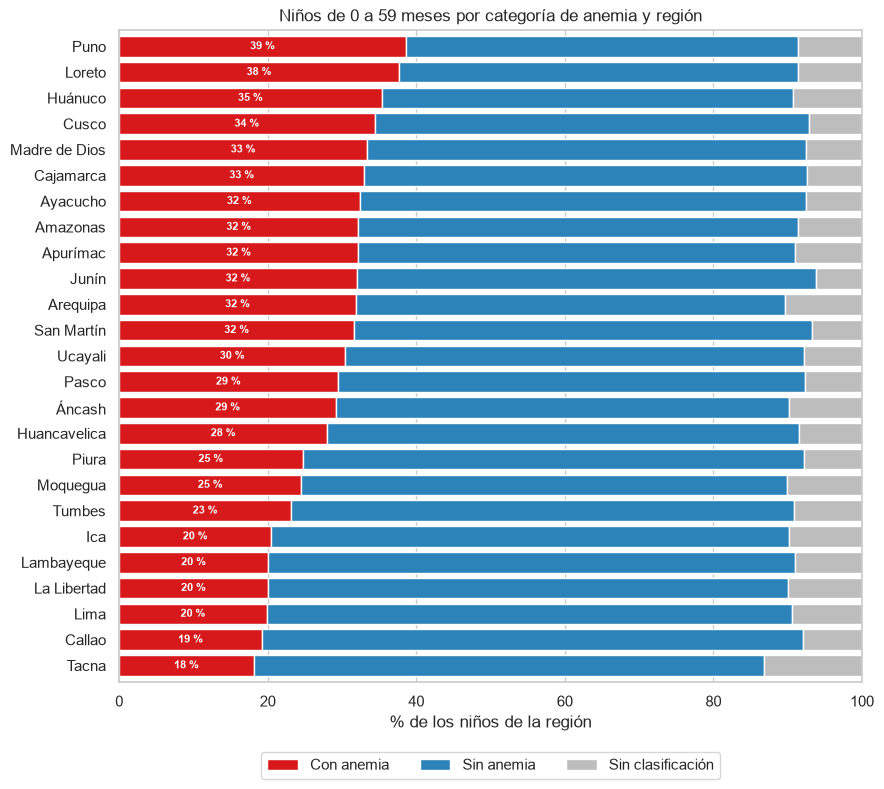

In [9]:
# % de cada categoria por region (cada fila suma 100 %)
CATEG = ["Con anemia", "Sin anemia", "Sin clasificación"]
COL_CATEG = {"Con anemia": "#d7191c", "Sin anemia": "#2b83ba", "Sin clasificación": "#bdbdbd"}

anemia_region = pd.crosstab(base["region"], base["categoria_anemia"], normalize="index").mul(100)[CATEG]
anemia_region = anemia_region.sort_values("Con anemia")                 # de menor a mayor % con anemia
tabla(anemia_region.sort_values("Con anemia", ascending=False), "t02_anemia_3categorias_region", decimales=1)

# Barras apiladas al 100 %: una barra por region
ax = anemia_region.plot(kind="barh", stacked=True, figsize=(9, 8), width=0.8,
                        color=[COL_CATEG[c] for c in CATEG])

for i, v in enumerate(anemia_region["Con anemia"]):          # etiqueta con el % con anemia
    ax.text(v / 2, i, f"{v:.0f} %", va="center", ha="center", color="white", fontsize=8, weight="bold")
ax.set(title="Niños de 0 a 59 meses por categoría de anemia y región", xlabel="% de los niños de la región", ylabel="")
ax.legend(title="", loc="lower center", bbox_to_anchor=(0.5, -0.16), ncol=3)
ax.set_xlim(0, 100)
guardar_fig("f01_anemia_3categorias_region")

**Interpretación:**
- **Rojo (con anemia):** varía mucho entre regiones: de 18 % en Tacna a 39 % en Puno. Es más alto en Puno, Loreto, Huánuco, Cusco y Madre de Dios, y más bajo en la costa (Tacna, Callao, Lima, La Libertad).
- **Gris (sin clasificación):** es parecido en todas las regiones (entre 6 y 13 %), porque se debe sobre todo a la **edad**: la ENDES no mide hemoglobina a los menores de 6 meses. No es un problema de una región en particular.
- Por eso, para el clustering se trabaja con los niños **clasificados** (6 a 59 meses). Los "sin clasificación" se reportan aquí, pero no pueden entrar al modelo porque no tienen hemoglobina.


## 5. Mejora 1: no usar hemoglobina imputada

La hemoglobina faltante se reemplazó por la mediana. Pero esos niños son justamente los "sin clasificación": casi todos bebés a los que nunca se les midió.

In [10]:
# Faltantes de hemoglobina por grupo de edad
t = pd.crosstab(pd.cut(base["edad_meses"], [-1, 5, 23, 59], labels=["0-5 meses", "6-23 meses", "24-59 meses"]),
                base["categoria_anemia"])[CATEG]
tabla(t, "t03_categoria_anemia_por_edad", decimales=0)

categoria_anemia,Con anemia,Sin anemia,Sin clasificación
edad_meses,,,
0-5 meses,0,0,1262
6-23 meses,2113,3389,133
24-59 meses,2951,8247,195


**Interpretación:** con la imputación, unos 1 600 niños (sobre todo bebés de 0 a 5 meses) entraban a K-means con una hemoglobina de **11,9 g/dL que nadie midió**.

**Decisión:** la población del clustering pasa a ser **niños de 6 a 59 meses con hemoglobina medida**, que es además la población que usa el MINSA para reportar anemia. Los 39 pares adicionales con peso o talla faltante también se excluyen en lugar de imputarlos.


## 6. Mejora 2: hemoglobina ajustada por altitud

A mayor altitud hay menos oxígeno y el cuerpo produce más hemoglobina, así que la hemoglobina **medida** sube con la altitud aunque el niño no esté mejor. Por eso el MINSA y la OMS **ajustan** la hemoglobina por altitud antes de diagnosticar anemia. La ENDES ya trae esa versión ajustada (`HC56A`, `HA56A`)

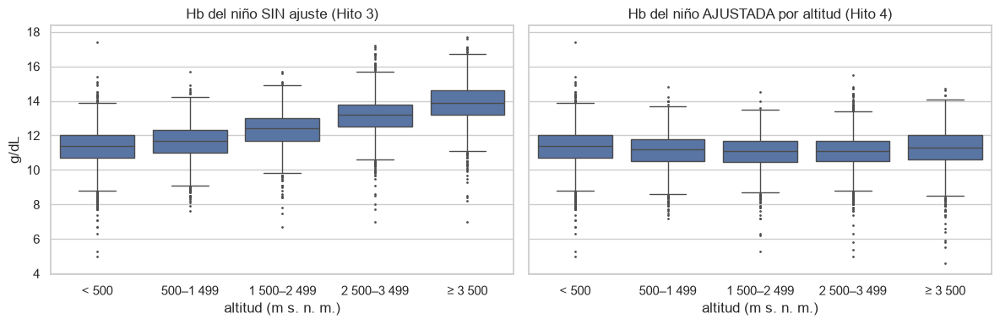

,correlación con la altitud
hb_nino_sin_ajuste,0.65
hb_nino,-0.08
hb_madre_sin_ajuste,0.66
hb_madre,0.08


In [11]:
# Tramos de altitud del hogar
base["tramo_altitud"] = pd.cut(base["altitud_m"], [0, 500, 1500, 2500, 3500, 6000], right=False,
                               labels=["< 500", "500–1 499", "1 500–2 499", "2 500–3 499", "≥ 3 500"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.boxplot(data=base, x="tramo_altitud", y="hb_nino_sin_ajuste", ax=ax[0], fliersize=1)
ax[0].set(title="Hb del niño SIN ajuste (Hito 3)", xlabel="altitud (m s. n. m.)", ylabel="g/dL")
sns.boxplot(data=base, x="tramo_altitud", y="hb_nino", ax=ax[1], fliersize=1)
ax[1].set(title="Hb del niño AJUSTADA por altitud (Hito 4)", xlabel="altitud (m s. n. m.)", ylabel="")
guardar_fig("f02_hb_ajuste_altitud")

# Correlacion de cada version con la altitud
corr = base[["hb_nino_sin_ajuste", "hb_nino", "hb_madre_sin_ajuste", "hb_madre", "altitud_m"]].corr()["altitud_m"]
tabla(corr.drop("altitud_m").rename("correlación con la altitud").to_frame(), "t04_correlacion_hb_altitud")

**Interpretación:** sin ajuste, la hemoglobina sube claramente con la altitud (panel izquierdo); ajustada, se mantiene casi plana (panel derecho). Con la versión sin ajuste, K-means agrupaba en parte por **geografía** y no por riesgo



## 7. Las dos matrices que se comparan

| | **Matriz B** |
|---|---|
| Niños | 6 a 59 meses con Hb medida |
| Faltantes | excluidos ("sin clasificación") |
| Hemoglobina | ajustada por altitud |
| Edad del niño | edad en meses |
| Resto de variables | edad, peso, talla y educación de la madre; peso y talla del niño|

En B la edad pasa a **meses**: al excluir a los menores de 6 meses, el grupo ordinal se queda casi sin su primer nivel, y la edad en meses conserva más información.

Las variables que **no** entran siguen las decisiones del Hito 3: `anemia` (variable de interés, solo describe), `sexo` (binaria nominal), `diferencia_hemoglobina` (redundante) y las variables territoriales (sirven para interpretar).

In [16]:
# ---------- Matriz B----------
VARS_B = ["edad_madre", "peso_madre", "talla_madre", "hb_madre", "educacion_madre",
          "peso_nino", "talla_nino", "hb_nino", "edad_meses"]
B = base[base["edad_meses"] >= 6].dropna(subset=VARS_B).reset_index(drop=True)

# Escalado z-score (StandardScaler)
XB = StandardScaler().fit_transform(B[VARS_B])
print("Matriz B:", XB.shape)

Matriz B: (16661, 9)


# PARTE III. K-means: configuraciones comparadas

| Criterio | Qué mide | Mejor |
|---|---|---|
| Inercia (codo) | Dispersión dentro de los grupos | donde la mejora se vuelve marginal |
| Silueta | Qué tan bien encaja cada niño en su grupo (−1 a 1) | ↑ |
| Davies-Bouldin | Dispersión interna / separación entre grupos | ↓ |
| Grupo más pequeño | Que no haya grupos marginales | ≥ 10 % |
| **Estabilidad (ARI)** | Si al repetir K-means con el 80 % de los niños salen los mismos grupos (0 a 1) | ↑ (> 0,8 = estable) |
| Rango de altitud entre grupos | Cuánto se agrupa por geografía en vez de por perfil | ↓ |


## 8. Funciones simples para evaluar

In [17]:
def evaluar(X, k):
    # Entrena K-means y devuelve las metricas internas
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEMILLA).fit(X)
    return {"k": k,
            "inercia": km.inertia_,
            "silueta": silhouette_score(X, km.labels_, sample_size=5000, random_state=1),
            "davies_bouldin": davies_bouldin_score(X, km.labels_),
            "grupo_min_%": 100 * np.bincount(km.labels_).min() / len(X)}

def estabilidad(X, k, repeticiones=10):
    # ARI promedio entre el modelo completo y modelos entrenados con el 80 % de los ninos
    completo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X).labels_
    rng = np.random.default_rng(0)
    aris = []
    for s in range(repeticiones):
        idx = rng.choice(len(X), int(0.8 * len(X)), replace=False)
        parcial = KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(X[idx])
        aris.append(adjusted_rand_score(completo[idx], parcial))
    return np.mean(aris)

def renumerar_por_anemia(etiquetas, anemia):
    # Renumera los grupos de menor a mayor % de anemia (0 = menos anemia), como en el Hito 3
    orden = pd.Series(anemia).groupby(etiquetas).mean().sort_values().index
    return pd.Series(etiquetas).map({viejo: nuevo for nuevo, viejo in enumerate(orden)}).to_numpy()

## 9. Matriz B: número de grupos k

,inercia,silueta,davies_bouldin,grupo_min_%,estabilidad_ARI
k,,,,,
2,113552.410,0.213,1.678,45.531,0.990
3,103434.530,0.147,2.069,29.680,0.978
4,96236.591,0.127,2.092,22.202,0.952
5,90755.887,0.127,1.996,15.455,0.947
6,86599.077,0.123,1.899,10.516,NaN
7,83119.441,0.116,1.964,9.387,NaN
8,80017.518,0.114,1.941,8.019,NaN


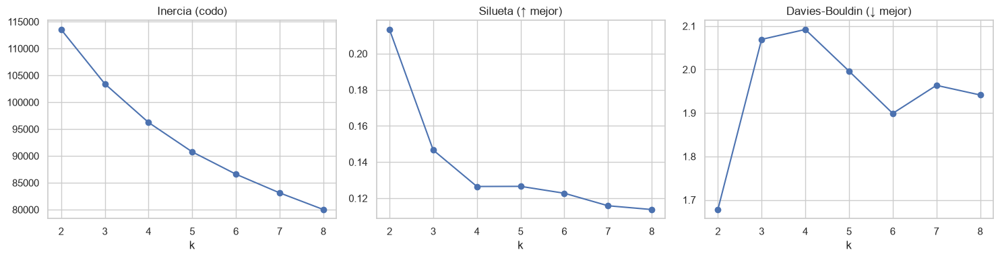

In [18]:
# Metricas de la matriz B para k = 2..8
res_B = pd.DataFrame([evaluar(XB, k) for k in range(2, 9)]).set_index("k")
# Estabilidad solo para k = 2..5 (los valores razonables; es la parte mas lenta)
res_B["estabilidad_ARI"] = [estabilidad(XB, k) if k <= 5 else np.nan for k in res_B.index]
tabla(res_B, "t05_metricas_por_k_matrizB", decimales=3)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(res_B.index, res_B["inercia"], marker="o");        ax[0].set(title="Inercia (codo)", xlabel="k")
ax[1].plot(res_B.index, res_B["silueta"], marker="o");        ax[1].set(title="Silueta (↑ mejor)", xlabel="k")
ax[2].plot(res_B.index, res_B["davies_bouldin"], marker="o"); ax[2].set(title="Davies-Bouldin (↓ mejor)", xlabel="k")
guardar_fig("f03_metricas_por_k")

**Interpretación:** las tres métricas internas apuntan a **k = 2**: mejor silueta, menor Davies-Bouldin y el único quiebre visible del codo. A partir de k = 3 la silueta es baja (< 0,15) y casi no cambia: los niños forman un continuo, no islas separadas.

## 10. Tabla comparativa de configuraciones K-means

la matriz B con k = 2, 3 y 4. Para cada una se mira también **cómo cambian la anemia y la altitud entre los grupos** (la anemia no forma los grupos: solo los describe).

In [19]:
configs = {"B, k=2": (XB, B, 2),
           "B, k=3": (XB, B, 3),
           "B, k=4": (XB, B, 4)}

filas = []
for nombre, (X, datos, k) in configs.items():
    fila = evaluar(X, k)
    fila["estabilidad_ARI"] = estabilidad(X, k)
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit_predict(X)
    por_grupo = datos.groupby(etiquetas)
    anemia_g = 100 * por_grupo["anemia"].mean()
    altitud_g = por_grupo["altitud_m"].mean()
    fila["anemia_min_%"], fila["anemia_max_%"] = anemia_g.min(), anemia_g.max()
    fila["rango_altitud_m"] = altitud_g.max() - altitud_g.min()
    filas.append(pd.Series(fila, name=nombre))

comparacion = pd.DataFrame(filas)
tabla(comparacion, "t06_comparacion_configuraciones", decimales=3)

,k,inercia,silueta,davies_bouldin,grupo_min_%,estabilidad_ARI,anemia_min_%,anemia_max_%,rango_altitud_m
"B, k=2",2.0,113552.410,0.213,1.678,45.531,0.990,20.804,41.735,64.742
"B, k=3",3.0,103434.530,0.147,2.069,29.680,0.978,16.987,42.700,397.482
"B, k=4",4.0,96236.591,0.127,2.092,22.202,0.952,15.936,53.670,391.735


**Lectura:**
- **B, k=2:** la mejor en todas las métricas, pero solo separa **niños pequeños de niños mayores**. Eso ya se sabía (la anemia se concentra entre 6 y 24 meses).
- **B, k=3 y B, k=4:** métricas peores que k=2 y parecidas entre sí; k=3 es algo mejor en silueta (0,147 frente a 0,127) y en estabilidad (0,98 frente a 0,95).

Antes de decidir entre 3 y 4 se usa una **segunda técnica**, el clustering jerárquico, para ver qué número de grupos sugiere un método distinto.

# PARTE IV. Clustering jerárquico (Ward) con dendrograma

El clustering **aglomerativo** empieza con cada niño como un grupo y va **fusionando** los dos grupos más parecidos hasta que queda uno solo. Con el método **Ward**, en cada paso se fusionan los dos grupos que menos aumentan la varianza interna (el mismo criterio que minimiza K-means). El **dendrograma** dibuja esas fusiones: la altura de cada unión es la **distancia de fusión**.

## 11. Matriz de enlace

In [20]:

# Cada fila de Z describe una fusion realizada por el algoritmo.
Z_ward = linkage(XB, method="ward")
print("Dimensión de la matriz de enlace:", Z_ward.shape)

# Mostramos las primeras fusiones (las de menor distancia: ninos casi identicos)
Z_ward_df = pd.DataFrame(Z_ward, columns=["grupo_1", "grupo_2", "distancia_fusion", "n_observaciones"])
display(Z_ward_df.head())

Dimensión de la matriz de enlace: (16660, 4)


,grupo_1,grupo_2,distancia_fusion,n_observaciones
0,6072.0,6073.0,0.056017,2.0
1,7992.0,7993.0,0.064816,2.0
2,2027.0,2028.0,0.069563,2.0
3,3320.0,3321.0,0.114973,2.0
4,7924.0,7925.0,0.134199,2.0


## 12. Dendrograma

Con 4 000 hojas el dendrograma completo es ilegible, así que se muestran solo las **últimas 30 fusiones** (`truncate_mode="lastp"`): cada hoja es un grupo y el número entre paréntesis es cuántos niños tiene.

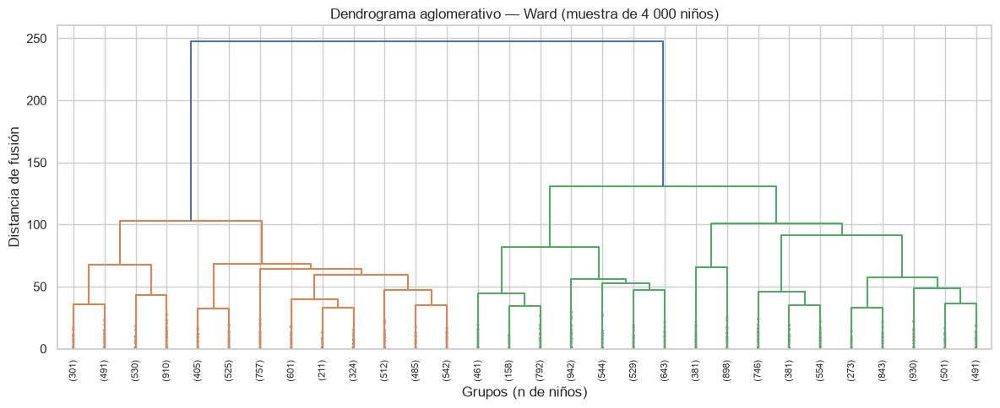

In [21]:
plt.figure(figsize=(12, 5))
dendrogram(Z_ward, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8, show_contracted=True)
plt.title("Dendrograma aglomerativo — Ward (muestra de 4 000 niños)")
plt.xlabel("Grupos (n de niños)")
plt.ylabel("Distancia de fusión")
guardar_fig("f04_dendrograma_ward")

## 13. ¿Punto de corte o número de clusters?

`fcluster` permite sacar los grupos del dendrograma de dos formas:

1. **Pedir un número de clusters** (criterion="maxclust"): sirve cuando ya sabemos cuántos grupos queremos.
2. **Dar una altura de corte** (criterion="distance"): se traza una línea horizontal y cada rama que queda debajo es un grupo. Es la forma que deja **decidir al dendrograma**: el mejor corte está donde hay un **salto grande** en la distancia de fusión, porque ahí se estarían uniendo grupos muy distintos.


,distancia_fusion,salto
grupos antes de fusionar,,
2,247.8,116.8
3,131.0,27.9
4,103.1,2.3
5,100.8,9.3
6,91.5,9.3
7,82.2,14.2
8,68.0,0.5
9,67.5,NaN


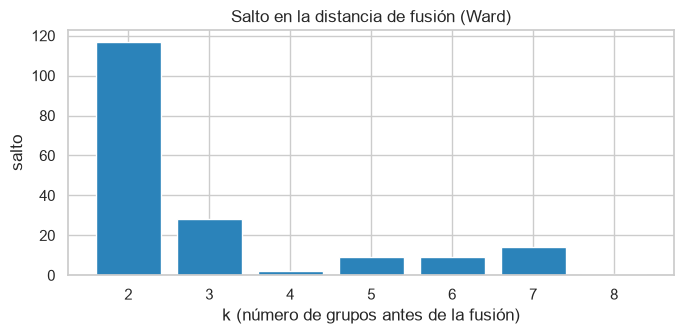

In [22]:
# Distancia de las ultimas 8 fusiones: la ultima fila pasa de 2 grupos a 1, la anterior de 3 a 2, etc.
ultimas = pd.DataFrame({"grupos antes de fusionar": range(2, 10),
                        "distancia_fusion": Z_ward[::-1, 2][:8]})

# Salto = cuanto sube la distancia respecto a la fusion anterior (k+1 -> k)
ultimas["salto"] = ultimas["distancia_fusion"] - ultimas["distancia_fusion"].shift(-1)
tabla(ultimas.set_index("grupos antes de fusionar"), "t07_saltos_dendrograma", decimales=1)

plt.figure(figsize=(7, 3.5))
plt.bar(ultimas["grupos antes de fusionar"][:-1].astype(str), ultimas["salto"][:-1], color="#2b83ba")
plt.title("Salto en la distancia de fusión (Ward)")
plt.xlabel("k (número de grupos antes de la fusión)"); plt.ylabel("salto")
guardar_fig("f05_saltos_dendrograma")

- El salto **más grande** está al pasar de **2 a 1** grupo: el dendrograma confirma que la división más fuerte es en 2 (niños pequeños frente a mayores), igual que las métricas de K-means.
- El **segundo salto** claro está al pasar de **3 a 2**.
- Desde 4 grupos hacia abajo los saltos son pequeños y parecidos.

**Decisión:** se usa la **altura de corte**, porque deja que la estructura de los datos elija el número de grupos. La línea se pone entre la fusión 4→3 y la 3→2, es decir, por encima del último salto pequeño y por debajo del segundo salto grande. Ese corte da **3 grupos**.

Altura de corte elegida: 117.0


,n
cluster,
0,6594
1,4069
2,5998


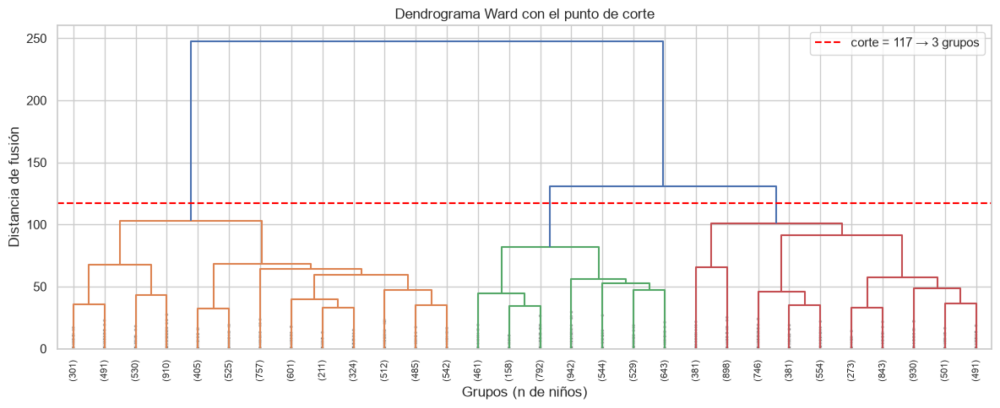

In [23]:
# Altura de corte: punto medio entre la fusion que pasa de 3 a 2 grupos y la que pasa de 4 a 3
altura_corte = (Z_ward[-2, 2] + Z_ward[-3, 2]) / 2
print(f"Altura de corte elegida: {altura_corte:.1f}")

labels_hier = fcluster(Z_ward, t=altura_corte, criterion="distance")
labels_hier = labels_hier - 1          # fcluster empieza en 1; se pasa a 0, 1, 2, ...

# Tamano de los grupos obtenidos
tamanos_hier = pd.Series(labels_hier, name="cluster").value_counts().sort_index()
display(tamanos_hier.to_frame("n"))

# Dendrograma con la linea de corte
plt.figure(figsize=(12, 5))
dendrogram(Z_ward, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8, show_contracted=True,
           color_threshold=altura_corte)
plt.axhline(altura_corte, color="red", ls="--", label=f"corte = {altura_corte:.0f} → 3 grupos")
plt.title("Dendrograma Ward con el punto de corte"); plt.xlabel("Grupos (n de niños)"); plt.ylabel("Distancia de fusión")
plt.legend()
guardar_fig("f06_dendrograma_corte")

## 14. Partición del dendrograma y comparación con K-means

Como en el código de clase, se dibuja la partición en dos dimensiones. Como los datos tienen 9 variables, se usan las **dos primeras componentes de PCA** como ejes `x1` y `x2`.

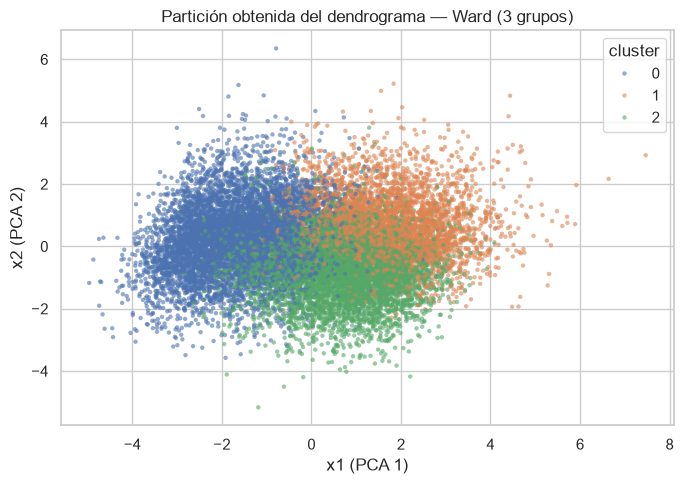

,edad_meses,peso_madre,talla_madre,educacion_madre,hb_nino,anemia,n
cluster_ward,,,,,,,
0,17.53,65.27,152.60,2.03,10.79,0.40,6594
1,44.42,73.53,155.82,2.35,11.66,0.19,4069
2,41.00,62.90,150.76,1.71,11.46,0.27,5998


In [26]:
# Ejes x1, x2 = dos primeras componentes PCA de la muestra (solo para dibujar)
hier_df = pd.DataFrame(PCA(n_components=2).fit_transform(XB), columns=["x1", "x2"])
viz_hier = hier_df.copy()
viz_hier["cluster"] = pd.Series(labels_hier).astype("category")

plt.figure(figsize=(7, 5))
ax = sns.scatterplot(data=viz_hier, x="x1", y="x2", hue="cluster", s=10, alpha=0.6, linewidth=0)
ax.set(title="Partición obtenida del dendrograma — Ward (3 grupos)", xlabel="x1 (PCA 1)", ylabel="x2 (PCA 2)")
guardar_fig("f07_particion_ward")

# Perfil de los 3 grupos de Ward (en unidades originales, con la anemia solo para describir)
muestra = B.assign(cluster_ward=labels_hier)
perfil_ward = muestra.groupby("cluster_ward")[["edad_meses", "peso_madre", "talla_madre", "educacion_madre", "hb_nino", "anemia"]].mean()
perfil_ward["n"] = tamanos_hier
tabla(perfil_ward, "t08_perfil_ward", decimales=2)


**Interpretación:**
- Ward también separa primero por **edad del niño** y luego divide a los mayores según el **nivel educativo de la madre**: un grupo de madres con poca educación tiene más anemia que el resto de los mayores.

# PARTE V. Decisión final y resultados

## 15. ¿k = 3 o k = 4?

| Evidencia | k = 2 | k = 3 | k = 4 |
|---|---|---|---|
| Silueta, Davies-Bouldin y codo (K-means) | **mejor** | intermedia | peor |
| Saltos del dendrograma (Ward) | salto mayor | **segundo salto** | sin salto |
| Estabilidad (ARI) | 0,99 | **0,98** | 0,95 |
| Acuerdo Ward–K-means | más alto | intermedio | más bajo |
| Aporta algo más que la edad | no | **sí** | sí |


Decisión: matriz B con k = 3.

## 16. Modelo final y perfil de cada grupo

In [27]:
K_FINAL = 3
# Un color por cluster (se usa en todas las figuras y mapas): azul = menos anemia ... rojo = mas anemia
COLORES = {0: "#2b83ba", 1: "#fdae61", 2: "#d7191c"}
modelo = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=10, random_state=SEMILLA).fit(XB)
B["cluster"] = renumerar_por_anemia(modelo.labels_, B["anemia"])

ETIQ = {"edad_madre": "Edad madre (años)", "peso_madre": "Peso madre (kg)", "talla_madre": "Talla madre (cm)",
        "hb_madre": "Hb madre (g/dL)", "educacion_madre": "Educ. madre (0–3)", "peso_nino": "Peso niño (kg)",
        "talla_nino": "Talla niño (cm)", "hb_nino": "Hb niño (g/dL)", "edad_meses": "Edad niño (meses)"}

# Perfil en unidades originales + composicion (variables que NO formaron los grupos)
perfil = B.groupby("cluster")[VARS_B].mean().rename(columns=ETIQ)
perfil["n"] = B["cluster"].value_counts().sort_index()
perfil["% del total"] = 100 * perfil["n"] / len(B)
perfil["% con anemia"] = 100 * B.groupby("cluster")["anemia"].mean()
perfil["% rural"] = 100 * (B["area"] == "Rural").groupby(B["cluster"]).mean()
perfil["altitud media (m)"] = B.groupby("cluster")["altitud_m"].mean()
tabla(perfil.T, "t10_perfil_clusters_final", decimales=1)

cluster,0,1,2
Edad madre (años),32.4,31.8,29.2
Peso madre (kg),75.0,60.5,64.7
Talla madre (cm),156.4,149.1,152.9
Hb madre (g/dL),12.8,12.4,12.6
Educ. madre (0–3),2.2,1.7,2.0
Peso niño (kg),16.7,14.3,10.1
Talla niño (cm),99.4,94.2,76.6
Hb niño (g/dL),11.8,11.4,10.7
Edad niño (meses),44.0,41.3,16.3
n,4945.0,5346.0,6370.0


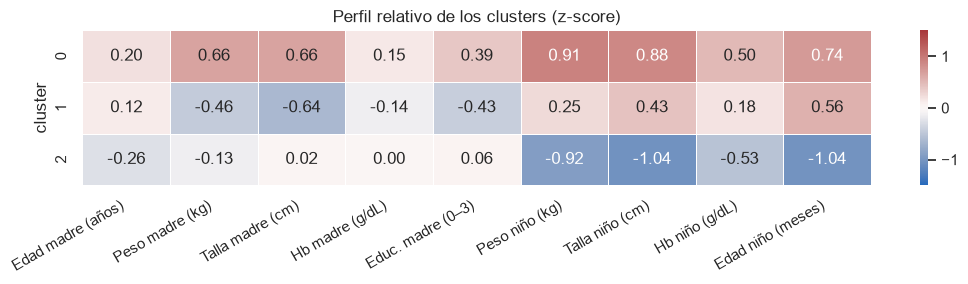

In [28]:
# Perfil relativo (z-score): cuantas desviaciones por encima/debajo de la media general
perfil_z = pd.DataFrame(XB, columns=VARS_B).groupby(B["cluster"]).mean().rename(columns=ETIQ)
plt.figure(figsize=(11, 3))
sns.heatmap(perfil_z, annot=True, fmt=".2f", center=0, cmap="vlag", vmin=-1.5, vmax=1.5, linewidths=0.5)
plt.title("Perfil relativo de los clusters (z-score)"); plt.ylabel("cluster"); plt.xticks(rotation=30, ha="right")
guardar_fig("f08_perfil_relativo_final")

### Nombre de cada perfil

Los nombres salen de leer la tabla y el heatmap anteriores. Los grupos están numerados de menor a mayor % de anemia, así que la numeración es estable:

| Cluster | Perfil | Rasgos principales |
|---|---|---|
| 0 | **Mayores, madre con más recursos** | ~3,5 años (44 meses); madre más alta, con más peso y más educación; mayormente urbano |
| 1 | **Mayores, madre en contexto vulnerable** | ~3,5 años (41 meses); madre de menor talla, peso y educación; más rural y a mayor altitud |
| 2 | **Pequeños (6 a 24 meses)** | ~1,5 años (16 meses); madre algo más joven, contexto materno cercano al promedio; **el grupo de mayor anemia** |

"Contexto vulnerable" resume una madre de menor talla y peso y con menor nivel educativo, en un hogar más rural y a mayor altitud. La talla baja de la madre es un indicador conocido de desnutrición acumulada.

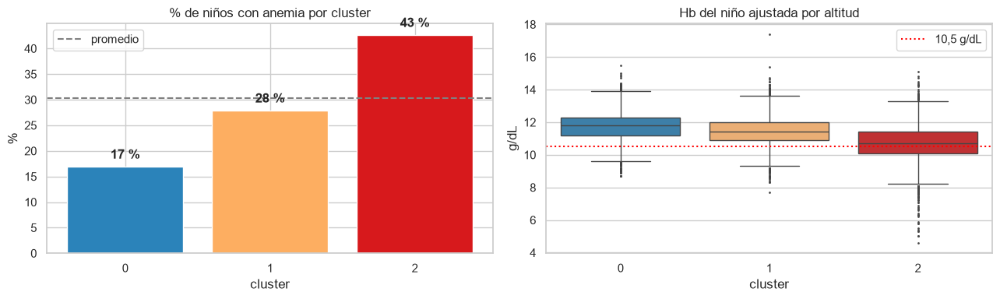

In [29]:
NOMBRES = {0: "Mayores, madre con más recursos",
           1: "Mayores, madre en contexto vulnerable",
           2: "Pequeños (6 a 24 meses)"}
B["perfil"] = B["cluster"].map(NOMBRES)

# Anemia por grupo: % con anemia y Hb del nino
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
prev = 100 * B.groupby("cluster")["anemia"].mean()
ax[0].bar(prev.index.astype(str), prev.values, color=[COLORES[c] for c in prev.index])
ax[0].axhline(100 * B["anemia"].mean(), color="gray", ls="--", label="promedio")
for i, v in enumerate(prev.values):
    ax[0].text(i, v + 1.5, f"{v:.0f} %", ha="center", weight="bold")
ax[0].set(title="% de niños con anemia por cluster", xlabel="cluster", ylabel="%"); ax[0].legend()
sns.boxplot(data=B, x="cluster", y="hb_nino", ax=ax[1], fliersize=1, palette=[COLORES[c] for c in range(K_FINAL)])
ax[1].axhline(10.5, color="red", ls=":", label="10,5 g/dL")
ax[1].set(title="Hb del niño ajustada por altitud", xlabel="cluster", ylabel="g/dL"); ax[1].legend()
guardar_fig("f09_anemia_por_cluster")

## 17. Visualización con PCA (solo para dibujar)

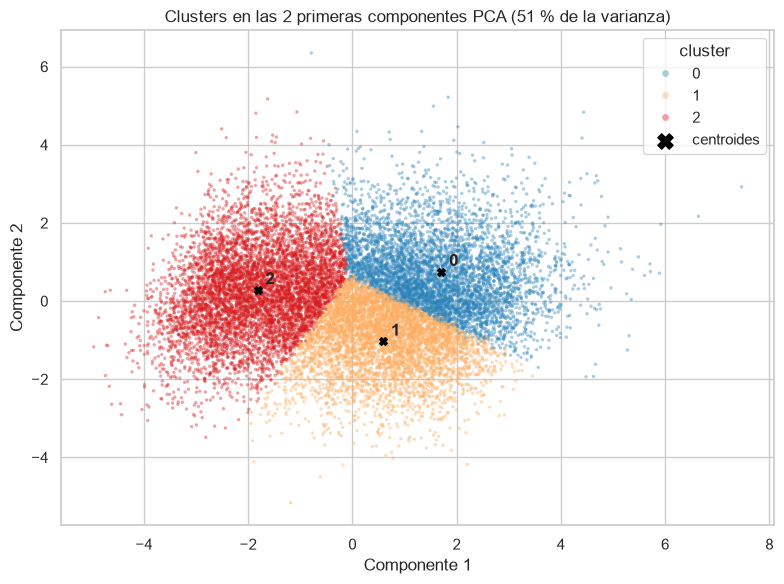

In [30]:
pca = PCA(n_components=2)
Z = pca.fit_transform(XB)
centros = pca.transform(modelo.cluster_centers_)
# Los centros estan en el orden original de K-means: se renumeran igual que los ninos
orden = pd.Series(B["cluster"].values, index=modelo.labels_).groupby(level=0).first()

plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=B["cluster"].astype(str), hue_order=[str(c) for c in range(K_FINAL)],
                palette=[COLORES[c] for c in range(K_FINAL)], s=6, alpha=0.4, linewidth=0)
plt.scatter(centros[:, 0], centros[:, 1], c="black", s=30, marker="X", label="centroides")
for i, (x, y) in enumerate(centros):
    plt.text(x + 0.15, y + 0.15, str(orden[i]), fontsize=12, weight="bold")
plt.title(f"Clusters en las 2 primeras componentes PCA ({100 * pca.explained_variance_ratio_.sum():.0f} % de la varianza)")
plt.xlabel("Componente 1"); plt.ylabel("Componente 2"); plt.legend(title="cluster", markerscale=2)
guardar_fig("f10_clusters_pca_final")

**Interpretación:** los grupos aparecen como **franjas de una misma nube**, no como islas. Esto coincide con la silueta baja: los perfiles sirven para describir y priorizar, pero la frontera entre grupos es gradual.

## 18. Dentro del grupo de mayor riesgo: ¿importa el contexto de la madre?

El cluster 2 junta a **todos** los niños pequeños. Se mira **de forma descriptiva** (sin crear un cuarto cluster) cómo cambia la anemia dentro de ese grupo según características de la madre que **no** definen la anemia.

n  % con anemia
característica        categoría                                 
Área                  Rural                 1843.0          49.9
                      Urbano                4527.0          39.8
Talla de la madre     baja                  2162.0          46.0
                      media                 2115.0          42.6
                      alta                  2093.0          39.4
Edad de la madre      < 25                  1718.0          44.6
                      25–34                 3116.0          42.2
                      35+                   1536.0          41.7
Educación de la madre sin educ. / primaria   805.0          50.8
                      secundaria            4574.0          43.4
                      superior               991.0          32.8

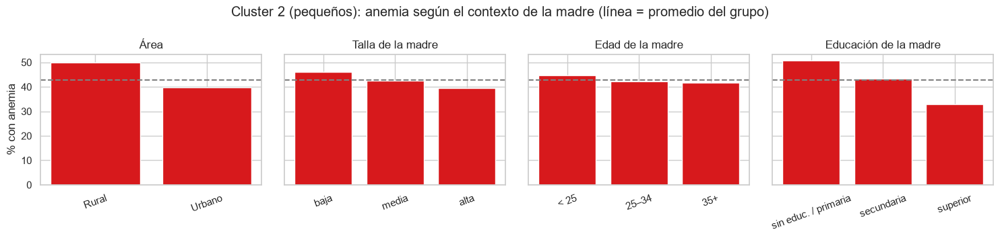

In [31]:
pequenos = B[B["cluster"] == 2].copy()
# Talla de la madre en tercios (bajo / medio / alto) dentro del grupo
pequenos["talla_madre_tercio"] = pd.qcut(pequenos["talla_madre"], 3, labels=["baja", "media", "alta"])
pequenos["edad_madre_grupo"] = pd.cut(pequenos["edad_madre"], [0, 24, 34, 49], labels=["< 25", "25–34", "35+"])
pequenos["educacion_txt"] = pd.Categorical(pequenos["educacion_madre"].map({0: "sin educ. / primaria", 1: "sin educ. / primaria",
                                                                            2: "secundaria", 3: "superior"}),
                                           categories=["sin educ. / primaria", "secundaria", "superior"], ordered=True)

filas = []
for var, nombre in [("area", "Área"), ("talla_madre_tercio", "Talla de la madre"),
                    ("edad_madre_grupo", "Edad de la madre"), ("educacion_txt", "Educación de la madre")]:
    g = pequenos.groupby(var, observed=True)["anemia"].agg(["size", "mean"])
    for cat, fila in g.iterrows():
        filas.append({"característica": nombre, "categoría": cat, "n": fila["size"], "% con anemia": 100 * fila["mean"]})
dentro_c2 = pd.DataFrame(filas).set_index(["característica", "categoría"])
tabla(dentro_c2, "t11_anemia_dentro_cluster2", decimales=1)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for a, (car, sub) in zip(ax, dentro_c2.groupby(level=0, sort=False)):
    sub = sub.droplevel(0)
    a.bar(sub.index.astype(str), sub["% con anemia"], color="#d7191c")
    a.axhline(100 * pequenos["anemia"].mean(), color="gray", ls="--")
    a.set(title=car, ylabel="% con anemia" if a is ax[0] else "")
    a.tick_params(axis="x", rotation=20)
plt.suptitle("Cluster 2 (pequeños): anemia según el contexto de la madre (línea = promedio del grupo)")
guardar_fig("f11_anemia_dentro_cluster2")

**Interpretación:** dentro de los niños pequeños, la anemia es más alta en zona **rural** (50 % frente a 40 %), cuando la madre tiene **menos educación** (51 % sin educación o con primaria frente a 33 % con superior) y cuando es de **menor talla** (46 % frente a 39 %). La edad de la madre casi no cambia el resultado. El contexto materno sigue importando, pero se muestra como **gradiente dentro del grupo** y no como un cluster aparte que las métricas no respaldan.

## 19. ¿En qué regiones pesa más el grupo de mayor riesgo?


,n_ninos,pct_cluster2,pct_cluster1,pct_anemia
region,,,,
Puno,420,37.4,30.2,42.4
Loreto,758,42.1,38.0,41.2
Huánuco,686,39.5,39.2,39.1
Cusco,470,37.7,36.2,36.8
Madre de Dios,665,40.3,28.3,36.1
Arequipa,515,43.5,23.7,35.7
Cajamarca,487,40.5,40.0,35.5
Apurímac,544,39.9,38.1,35.5
Amazonas,727,42.2,36.3,35.4


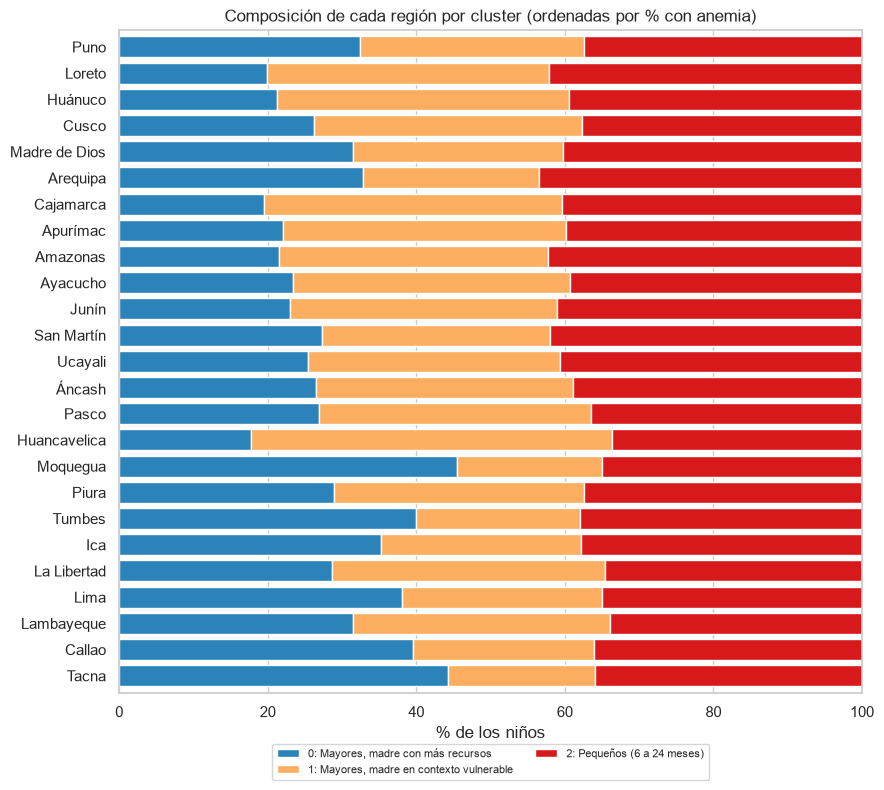

In [32]:
por_region = B.groupby("region").agg(n_ninos=("HHID", "size"),
                                      pct_cluster2=("cluster", lambda s: 100 * (s == 2).mean()),
                                      pct_cluster1=("cluster", lambda s: 100 * (s == 1).mean()),
                                      pct_anemia=("anemia", lambda s: 100 * s.mean()))
por_region = por_region.sort_values("pct_anemia", ascending=False)
tabla(por_region, "t12_clusters_por_region", decimales=1)

# Composicion de cada region por cluster (barras apiladas al 100 %)
comp = pd.crosstab(B["region"], B["cluster"], normalize="index").mul(100)
comp = comp.loc[por_region.index[::-1]]               # mismo orden que la tabla (mas anemia arriba)
ax = comp.plot(kind="barh", stacked=True, figsize=(9, 8), width=0.8, color=[COLORES[c] for c in range(K_FINAL)])
ax.set(title="Composición de cada región por cluster (ordenadas por % con anemia)", xlabel="% de los niños", ylabel="")
ax.legend([f"{c}: {NOMBRES[c]}" for c in range(K_FINAL)], loc="lower center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8)
ax.set_xlim(0, 100)
guardar_fig("f12_clusters_por_region")

# PARTE VI. Mapas HTML (Hito 3, con la configuración final)

Se rehacen los mapas del Hito 3 con la matriz B y k = 3. Recordatorio: Folium usa **`[latitud, longitud]`**, al revés que los ejes x-y.

| Mapa | Contenido |
|---|---|
| m01 | Centros poblados con anemia alta (círculos con popup) |
| m02 | Mapa de calor de niños con anemia / de todos los niños |
| m03 | Coroplético: % de anemia por región (shapefile `adm1`) |
| m04 | DBSCAN espacial: zonas de centros con anemia alta |
| m05 | Mapa final con todas las capas |

## 20. Una fila por centro poblado

In [33]:
CLAVE_CP = ["UBIGEO", "centro_poblado", "latitud", "longitud"]

cp = B.groupby(CLAVE_CP).agg(region=("region", "first"),
                             n_ninos=("HHID", "size"),
                             casos=("anemia", "sum"),
                             altitud_m=("altitud_m", "mean"),
                             cluster_dominante=("cluster", lambda s: s.mode().iloc[0])).reset_index()
cp["prev"] = 100 * cp["casos"] / cp["n_ninos"]
# % de ninos del centro en cada cluster (para el popup)
pct_cl = (pd.crosstab([B[c] for c in CLAVE_CP], B["cluster"], normalize="index").mul(100)
          .add_prefix("pct_cluster_").reset_index())      # columnas pct_cluster_0, pct_cluster_1, ...
cp = cp.merge(pct_cl, on=CLAVE_CP, how="left")
cp_gdf = gpd.GeoDataFrame(cp, geometry=gpd.points_from_xy(cp["longitud"], cp["latitud"]), crs="EPSG:4326")

# Centros con anemia alta: al menos 5 ninos y >= 40 % con anemia (umbrales del Hito 3)
UMBRAL_ALTA, MIN_NINOS_CP = 40, 5
alta = cp_gdf[(cp_gdf["n_ninos"] >= MIN_NINOS_CP) & (cp_gdf["prev"] >= UMBRAL_ALTA)].copy()
print("Centros poblados:", len(cp_gdf), "| con anemia alta:", len(alta))

Centros poblados: 3766 | con anemia alta: 617


## 21. m01 : Centros poblados con anemia alta

In [34]:
mapa1 = folium.Map(location=[-9.2, -75.0], zoom_start=5, tiles=MAPA_BASE)
for _, f in alta.iterrows():
    texto = (f"<b>{f['centro_poblado']}</b> ({f['region']})<br>Niños: {f['n_ninos']}<br>"
             f"Con anemia: {f['prev']:.0f} %<br>Altitud: {f['altitud_m']:.0f} m<br>Cluster dominante: {f['cluster_dominante']}")
    folium.CircleMarker(location=[f["latitud"], f["longitud"]], radius=3 + f["n_ninos"] ** 0.5,   # mas ninos = mas grande
                        color="darkred", fill=True, fill_opacity=0.5,
                        popup=folium.Popup(texto, max_width=250)).add_to(mapa1)
mapa1.save(DIR_MAP / "m01_centros_anemia_alta.html")
mapa1

**Interpretación:** cada círculo es un centro poblado con al menos 5 niños y 40 % o más con anemia; el tamaño crece con el número de niños. Aparecen en casi todas las regiones, también en la costa, así que el promedio regional esconde focos locales.

## 22. m02  : Mapas de calor

In [35]:
rojos = {0.2: "#fdbb84", 0.4: "#fc8d59", 0.6: "#e34a33", 0.8: "#b30000", 1.0: "#7f0000"}
pts_anemia = B.loc[B["anemia"] == 1, ["latitud", "longitud"]].values.tolist()
pts_todos  = B[["latitud", "longitud"]].values.tolist()
print("Niños con anemia:", len(pts_anemia), "| todos:", len(pts_todos))

mapa2 = folium.Map(location=[-9.2, -75.0], zoom_start=5, tiles=MAPA_BASE)
HeatMap(pts_anemia, radius=8, blur=10, gradient=rojos, min_opacity=0.3).add_to(mapa2)
mapa2.save(DIR_MAP / "m02_calor_ninos_con_anemia.html")
mapa2

Niños con anemia: 5054 | todos: 16661


**Interpretación:** el calor de los niños **con anemia** (m02) se parece mucho al de **todos** los niños (m03), porque ambos siguen el diseño de la muestra: donde se encuestó más, hay más puntos. Por eso las conclusiones territoriales se basan en **porcentajes** (m01, m04), no en la densidad.

## 23. m03 : Coroplético: anemia por región

In [36]:
# Tasa de anemia por region (se agrupa por el codigo del shapefile)
reg_tasa = (B.groupby("ADM1_PCODE")
              .agg(n_ninos=("HHID", "size"), tasa_anemia=("anemia", "mean"),
                   pct_cluster2=("cluster", lambda s: (s == 2).mean()), hb_nino_media=("hb_nino", "mean"))
              .reset_index())
reg_tasa[["tasa_anemia", "pct_cluster2"]] = (100 * reg_tasa[["tasa_anemia", "pct_cluster2"]]).round(1)
reg_tasa["hb_nino_media"] = reg_tasa["hb_nino_media"].round(2)

# Une los poligonos de las regiones con la tasa y simplifica los bordes (1 km) para que cargue rapido
mapa_reg = regiones[["ADM1_PCODE", "ADM1_ES", "geometry"]].merge(reg_tasa, on="ADM1_PCODE", how="left")
mapa_reg["geometry"] = mapa_reg.to_crs(crs_metros).simplify(1000).to_crs(regiones.crs)

mapa4 = mapa_reg.explore(column="tasa_anemia", cmap="OrRd", legend=True, tiles=MAPA_BASE,
                         tooltip=["ADM1_ES", "n_ninos", "tasa_anemia", "pct_cluster2", "hb_nino_media"],
                         style_kwds={"color": "gray", "weight": 0.5})
mapa4.save(DIR_MAP / "m04_coropletico_anemia_region.html")
mapa4

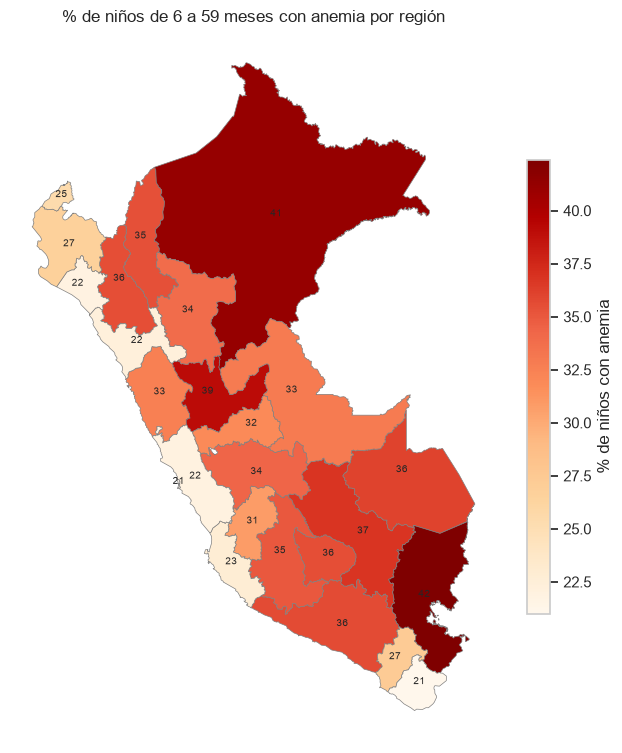

In [37]:
# Version estatica del coropletico para el paper
fig, ax = plt.subplots(figsize=(6.5, 8))
mapa_reg.plot(column="tasa_anemia", cmap="OrRd", edgecolor="gray", linewidth=0.5, legend=True, ax=ax,
              legend_kwds={"label": "% de niños con anemia", "shrink": 0.6})
for _, f in mapa_reg.iterrows():
    p = f["geometry"].representative_point()
    ax.text(p.x, p.y, f"{f['tasa_anemia']:.0f}", fontsize=7, ha="center")
ax.set_title("% de niños de 6 a 59 meses con anemia por región"); ax.set_axis_off()
guardar_fig("f13_coropletico_anemia_region")

**Interpretación:** la anemia es más alta en Puno, Loreto, Huánuco, Cusco y Madre de Dios, y más baja en la costa (Callao, Tacna, Lima, Lambayeque, La Libertad). Con la hemoglobina ajustada por altitud, las regiones altoandinas ya no se ven artificialmente "sanas".


## 24. m04 : DBSCAN espacial: zonas de centros con anemia alta

DBSCAN usa las **ubicaciones** (no las variables del niño) de los centros con anemia alta para encontrar **zonas** donde se concentran. Las distancias se miden en metros (UTM).

In [38]:
alta_m = alta.to_crs(crs_metros)
coords_m = np.column_stack([alta_m.geometry.x, alta_m.geometry.y])   # una fila por centro, x-y en metros

MIN_SAMPLES = 8
filas = []
for eps_km in [25, 50, 100]:
    etiq = DBSCAN(eps=eps_km * 1000, min_samples=MIN_SAMPLES).fit_predict(coords_m)
    tam_g = pd.Series(etiq[etiq != -1]).value_counts()
    filas.append({"eps (km)": eps_km, "zonas": len(tam_g), "centros como ruido": int((etiq == -1).sum()),
                  "zona más grande (centros)": int(tam_g.max()) if len(tam_g) else 0})
tabla(pd.DataFrame(filas).set_index("eps (km)"), "t14_dbscan_eps", decimales=0)

# eps elegido: 50 km (escala regional, como en el Hito 3)
alta["zona"] = DBSCAN(eps=50_000, min_samples=MIN_SAMPLES).fit_predict(coords_m)
perfil_zonas = (alta[alta["zona"] != -1].groupby("zona")
                .agg(centros=("zona", "size"), ninos=("n_ninos", "sum"), casos=("casos", "sum"),
                     altitud_media=("altitud_m", "mean"), region_principal=("region", lambda s: s.mode()[0])))
perfil_zonas["prevalencia_%"] = 100 * perfil_zonas["casos"] / perfil_zonas["ninos"]
tabla(perfil_zonas.sort_values("ninos", ascending=False), "t15_perfil_zonas_dbscan", decimales=1)

alta["grupo"] = alta["zona"].astype(str)
alta.loc[alta["zona"] == -1, "grupo"] = "ruido"
mapa6 = alta[alta["grupo"] == "ruido"].explore(color="lightgray", marker_kwds={"radius": 2}, tiles=MAPA_BASE, name="ruido")
alta[alta["grupo"] != "ruido"].explore(m=mapa6, column="grupo", categorical=True, cmap="tab20",
                                       marker_kwds={"radius": 4}, legend=False, name="zonas DBSCAN",
                                       tooltip=["grupo", "centro_poblado", "region", "n_ninos", "prev"])
mapa6.save(DIR_MAP / "m06_dbscan_zonas_anemia_alta.html")
mapa6

,zonas,centros como ruido,zona más grande (centros)
eps (km),,,
25,17,338,39
50,18,124,98
100,5,17,481


,centros,ninos,casos,altitud_media,region_principal,prevalencia_%
zona,,,,,,
3,98,608,327.0,2950.6,Ayacucho,53.8
0,67,440,229.0,964.6,San Martín,52.0
7,53,330,175.0,1777.0,Huánuco,53.0
6,41,250,122.0,323.8,Lima,48.8
17,28,186,99.0,160.9,Ucayali,53.2
12,28,168,93.0,307.4,Madre de Dios,55.4
4,25,144,72.0,2359.9,Arequipa,50.0
16,23,137,74.0,25.2,Tumbes,54.0
14,19,117,62.0,45.5,Piura,53.0


**Interpretación:** con `eps` = 50 km, DBSCAN encuentra 18 zonas donde los centros con anemia alta están juntos; las más grandes están en Ayacucho, San Martín y Huánuco, todas con más de 50 % de anemia. Los puntos grises son centros con anemia alta pero **aislados**. Es un complemento territorial: dice **dónde** se concentra el problema, mientras que K-means dice **a quién** afecta.

## 25. m05 : Mapa final con todas las capas

In [39]:
mapa7 = folium.Map(location=[-9.2, -75.0], zoom_start=5, tiles=MAPA_BASE)

# Capa 1: coropletico de la tasa de anemia por region
folium.Choropleth(geo_data=mapa_reg[["ADM1_PCODE", "ADM1_ES", "tasa_anemia", "geometry"]],
                  data=mapa_reg, columns=["ADM1_PCODE", "tasa_anemia"],
                  key_on="feature.properties.ADM1_PCODE",              # es como el on= de un merge
                  fill_color="OrRd", fill_opacity=0.6, line_weight=0.5,
                  legend_name="% de niños con anemia", name="Anemia por región").add_to(mapa7)

# Capa 2: mapa de calor (apagada)
capa_calor = folium.FeatureGroup(name="Mapa de calor (niños con anemia)", show=False)
HeatMap(pts_anemia, radius=8, blur=10, gradient=rojos, min_opacity=0.3).add_to(capa_calor)
capa_calor.add_to(mapa7)

# Capa 3: centros con anemia alta
capa_alta7 = folium.FeatureGroup(name=f"Centros con anemia ≥ {UMBRAL_ALTA} %")
for _, f in alta.iterrows():
    folium.CircleMarker(location=[f["latitud"], f["longitud"]], radius=3 + f["n_ninos"] ** 0.5,
                        color="darkred", fill=True, fill_opacity=0.5,
                        popup=f"<b>{f['centro_poblado']}</b> ({f['region']})<br>{f['prev']:.0f} % de {f['n_ninos']} niños").add_to(capa_alta7)
capa_alta7.add_to(mapa7)

# Capa 4: cluster K-means dominante (apagada)
capa_km = folium.FeatureGroup(name="Cluster K-means dominante", show=False)
for _, f in cp.iterrows():
    folium.CircleMarker(location=[f["latitud"], f["longitud"]], radius=3, color=COLORES[f["cluster_dominante"]],
                        fill=True, fill_opacity=0.7,
                        popup=f"Cluster {f['cluster_dominante']} · {f['centro_poblado']}").add_to(capa_km)
capa_km.add_to(mapa7)

folium.LayerControl().add_to(mapa7)
mapa7.save(DIR_MAP / "m07_mapa_final_capas.html")
mapa7

**Cómo usarlo:** con el selector de capas (arriba a la derecha) se combina el **contexto regional** (coroplético) con el **detalle local** (centros con anemia alta y clusters). Por ejemplo, se pueden encontrar centros de anemia alta dentro de regiones con tasa media, que el promedio regional esconde.

# PARTE VII. Archivos de salida y registro de decisiones

- `resultados/matriz_final_clusters.csv`: la matriz B sin escalar, con el cluster y el perfil de cada niño.
- `figuras/*.png` y `tablas/*.csv|*.tex`: las figuras y tablas del paper.
- `mapas/*.html`: los mapas interactivos (el principal es `mapa_clusters.html`).

In [40]:
Path("resultados").mkdir(exist_ok=True)
cols = ["HHID", "orden_madre"] + VARS_B + ["sexo", "anemia", "region", "area", "altitud_m",
                                           "centro_poblado", "latitud", "longitud", "cluster", "perfil"]
B[cols].to_csv("resultados/matriz_final_clusters.csv", index=False, encoding="utf-8-sig")

print("Figuras:", len(list(DIR_FIG.glob("*.png"))), "| Tablas:", len(list(DIR_TAB.glob("*.csv"))),
      "| Mapas:", len(list(DIR_MAP.glob("*.html"))))

Figuras: 13 | Tablas: 13 | Mapas: 5


## Conclusión
La anemia infantil varía mucho entre regiones: desde alrededor de 18 % en Tacna hasta 39 % en Puno. Es más alta en Puno, Loreto, Huánuco, Cusco y Madre de Dios, y más baja en la costa. Las métricas internas de K-means (silueta, Davies-Bouldin y codo) favorecían k = 2. Esa división solo separaba a los niños pequeños de los mayores, algo que ya se sabía. Por eso se eligió k = 3, que además tuvo respaldo del dendrograma de Ward (segundo salto claro al pasar de 3 a 2 grupos) y una estabilidad alta (ARI de 0,98). Los tres perfiles son:

Niños pequeños (6 a 24 meses): es el grupo con mayor anemia.
Niños mayores con madre en contexto más favorable: madre de mayor talla, peso y educación, y mayormente urbano.
Niños mayores con madre en contexto vulnerable: madre de menor talla, peso y educación, más rural y a mayor altitud.

Dentro del grupo de mayor riesgo, la anemia aumenta en zonas rurales, cuando la madre tiene menor educación y cuando es de menor talla. Esto muestra que el contexto materno actúa como un gradiente y no como un cluster aparte.

Como limitación, la silueta baja y la visualización con PCA muestran que los grupos son franjas de una misma nube y no islas separadas. Por eso los perfiles sirven para describir y priorizar, pero la frontera entre ellos es gradual.

En el plano territorial, los mapas muestran que el promedio regional esconde focos locales: hay centros poblados con anemia alta incluso en regiones de tasa baja o media. DBSCAN identificó 18 zonas de concentración, las mayores en Ayacucho, San Martín y Huánuco, con más de 50 % de anemia. Mientras K-means indica a quién afecta la anemia, DBSCAN indica dónde se concentra. Las dos miradas se complementan y permiten orientar intervenciones a las edades más críticas y a los territorios y contextos maternos más vulnerables. Las conclusiones territoriales se apoyan en porcentajes y no en densidad, porque los mapas de calor siguen el diseño muestral de la encuesta.